In [1]:
from _test_utils import TestLogger
from PicoTest import Pico
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
logger = TestLogger()

In [4]:
#connect and initialize Pico
pico = Pico(logger=logger)
pico.initialize()
pico.isConnected

True

In [ ]:
pico.loadSettings()

In [ ]:
pico.selectMethod('default')

In [ ]:
# run any give script
sc = """

"""
res = pico.runScript(sc,parseValue=True)


In [ ]:
# scan and plot one channel.
v,a = pico.scanChannel('C3')
plt.plot(v,a)

In [5]:
#open a channel
pico.openChannel('C1')

'e\nset_gpio_cfg 96 1\nset_gpio 0i\n\n'

['e\n', '\n']

In [11]:
# manual script 
sc = """e
var c
var p
var f
var r
set_pgstat_chan 0
set_pgstat_mode 3
set_max_bandwidth 400
set_pot_range -600m 0m
set_autoranging 100u 100u
cell_on
set_e -600m
wait 200m
meas_loop_swv p c f r -600m 0m 50m 50m 100
	pck_start
	pck_add p
	pck_add c
	pck_add f    
	pck_add r
	pck_end
endloop
on_finished:
cell_off

"""

In [12]:
res = pico.runScript(sc,parseValue=True)

In [13]:
p = np.array([i[0] for i in res[1][0]])
c = np.array([i[1]*1e6 for i in res[1][0]])
f = np.array([i[2]*1e6 for i in res[1][0]])
r = np.array([i[3]*1e6 for i in res[1][0]])

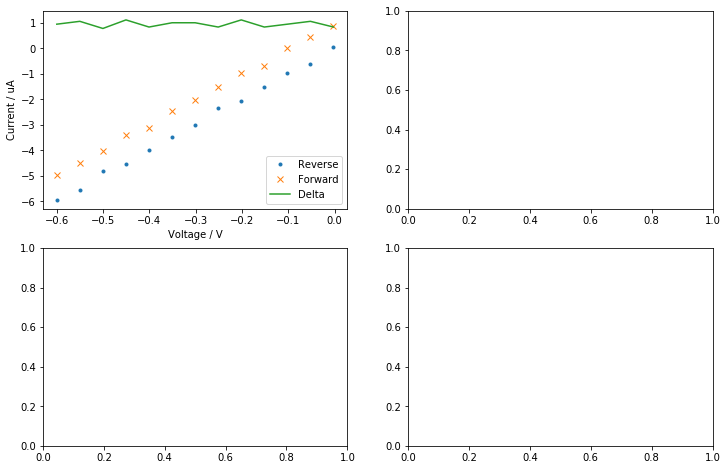

In [18]:
fig,axes = plt.subplots(2,2,figsize=(12,8))
ax = axes[0][0]
ax.plot(p,r,'.',label='Reverse')
ax.plot(p,f,'x',label='Forward')
ax.plot(p,c,'-',label='Delta')
ax.legend()
ax.set_ylabel('Current / uA')
ax.set_xlabel('Voltage / V')
plt.show()

In [38]:
r[0]

1607.1360000000002